In [1]:
#use packages and files

# import Pkg; Pkg.add("GLM")
println("test")
using LinearAlgebra
using SparseArrays
include("Spin_ED_dario.jl")
BLAS.set_num_threads(1)
using Plots
using LaTeXStrings
using CairoMakie
CairoMakie.activate!((type = "svg"))
using KrylovKit
# using Colors, ColorSchemes
# using GLM
using FFTW
using Interpolations
using JLD2
using Optim
using HDF5
using Random

test


In [ ]:
#if there is a missing package:
#import Pkg; Pkg.add("HDF5")

# Example of spin dynamics

In [2]:
#single spin

#initial state

S = 1

init = init_cssX(S)

3-element Vector{Float64}:
 0.5
 0.7071067811865476
 0.5

In [3]:
#building Hamiltonian

Jz = Sz(S)
Ham = Jz*Jz #OAT Hamiltonian

3×3 Matrix{Float64}:
 1.0  0.0  0.0
 0.0  0.0  0.0
 0.0  0.0  1.0

In [8]:
#time evolution

tlen = 201
tmax = 2*pi
les_t = range(0, tmax, tlen)

vp, P, Pm = diagonalisation(Ham)

#observable : mean and variance of Jx
Jx = Sx(S)
Jx2 = Jx*Jx

MeanX = zeros(Float64, tlen)
VarX = zeros(Float64, tlen)
for kt in 1:tlen
    t = les_t[kt]
    psi_t = evolution(vp, P, Pm, init, t)
    mx = real(psi_t'*Jx*psi_t)
    MeanX[kt] = mx
    VarX[kt] = real(psi_t'*Jx2*psi_t) - mx*mx
end

#for saving the data, then use load_object to reopen them
# path = "C:/Users/trifa/OneDrive/Documents/papers/Little_cats/Figures"
# save_object("$path/test_evolution_Jx_S$(S).jld2", MeanX)
# save_object("$path/test_evolution_time_S$(S).jld2", les_t)
# save_object("$path/test_evolution_VarX_S$(S).jld2", VarX)

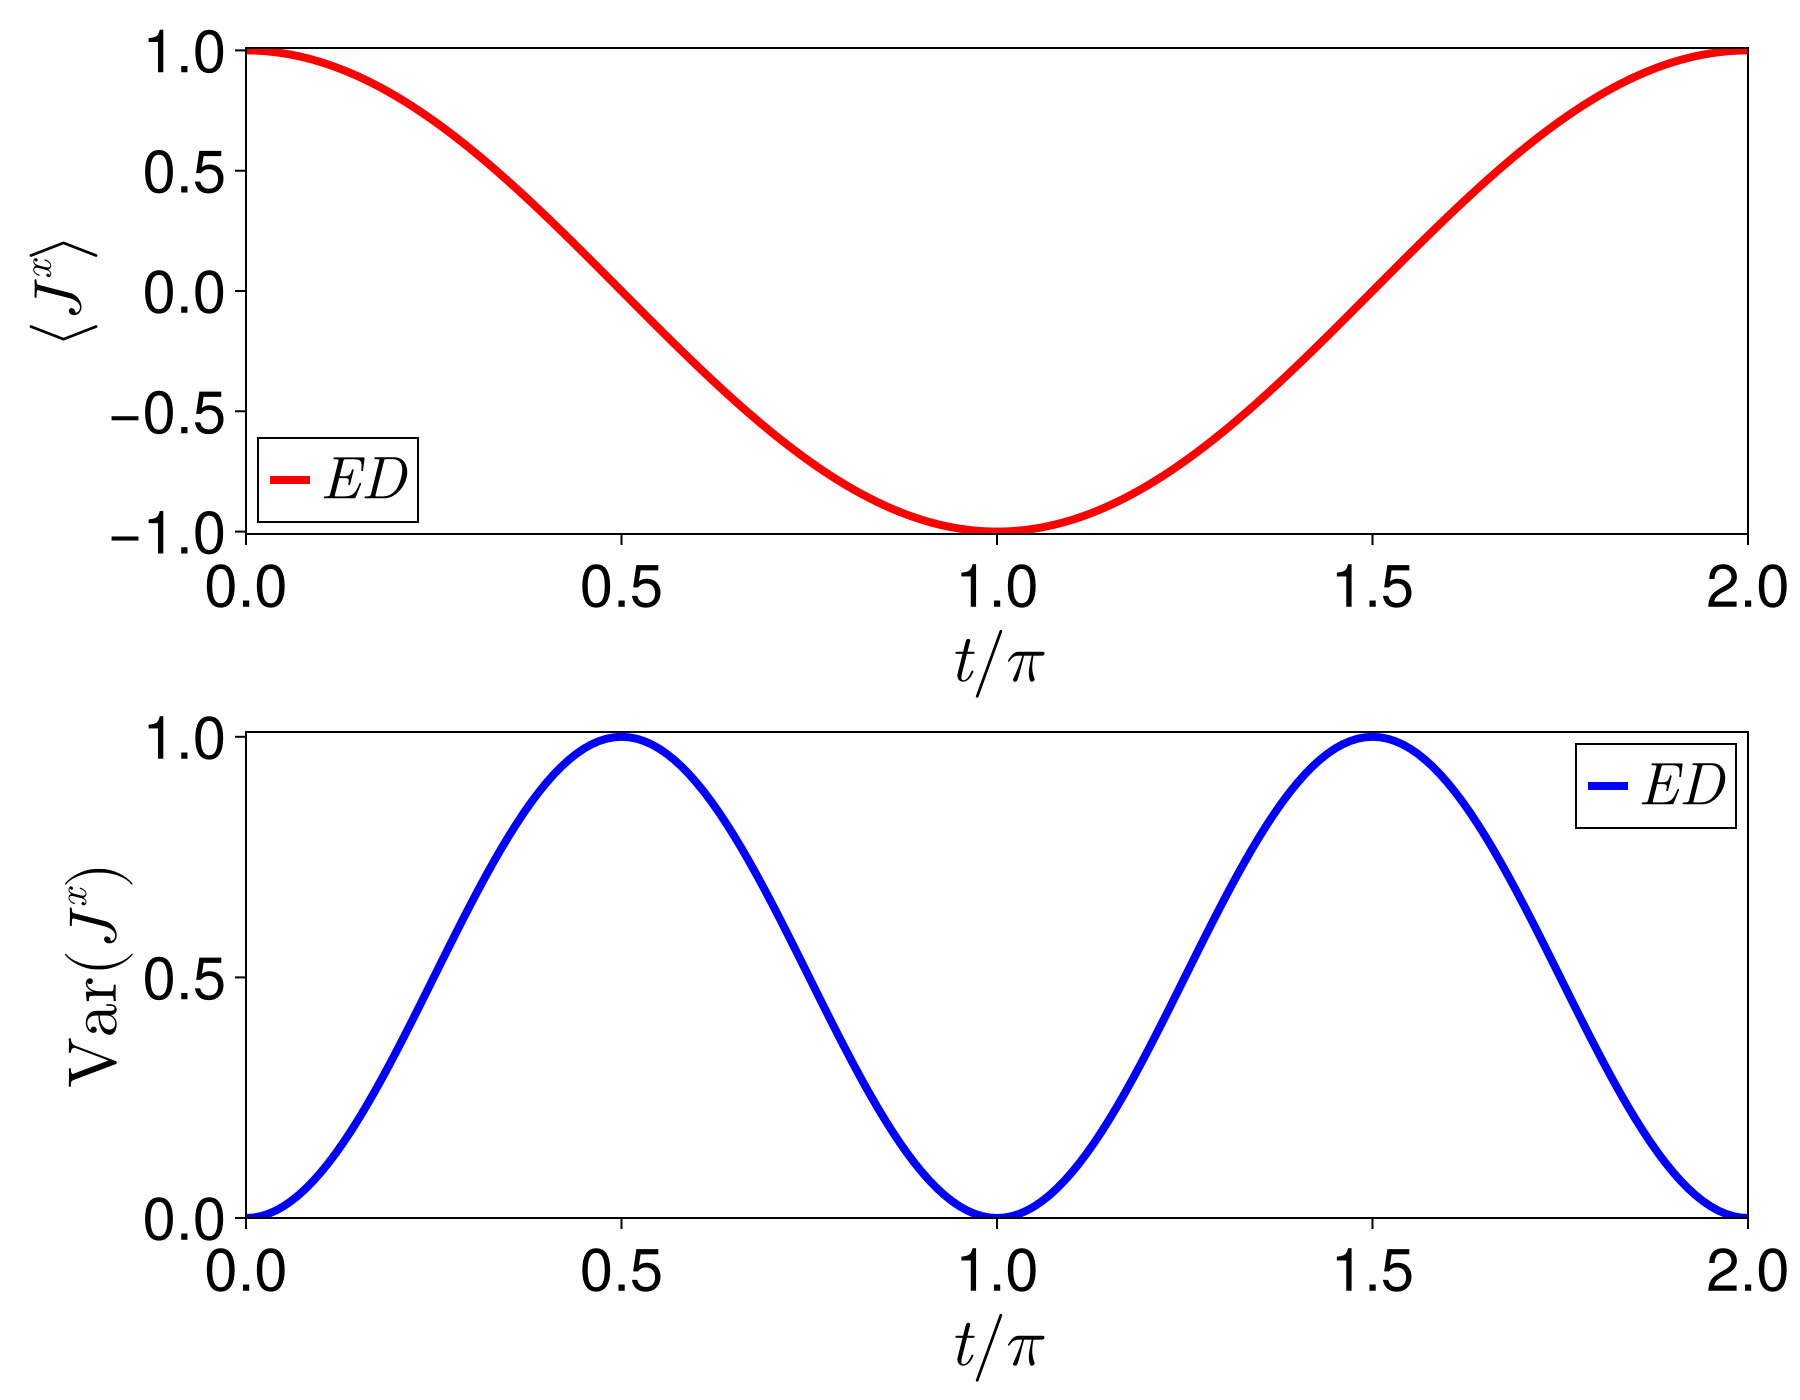

In [12]:
#plotting

f = Figure(font="Helvetica", figure_padding=(10, 26, 10, 24), size=(900, 700), backgroundcolor=:white, fontsize=30, tickfontsize=30)
ax1 = Axis(f[1, 1], xlabel= L"t/\pi", ylabel=L"\langle J^{x} \rangle", xlabelsize=34, ylabelsize=34, xgridvisible = false, ygridvisible = false)
ax2 = Axis(f[2, 1], xlabel= L"t/\pi", ylabel=L"\mathrm{Var} ( J^{x} )", xlabelsize=34, ylabelsize=34, xgridvisible = false, ygridvisible = false)


lines!(ax1, les_t/pi, MeanX; linewidth=4, label=L"ED", color = :red)
lines!(ax2, les_t/pi, VarX; linewidth=4, label=L"ED", color = :blue)

axislegend(ax1, position = :lb)
axislegend(ax2, position = :rt)

limits!(ax1, 0, tmax/pi, -S*1.01, S*1.01)
limits!(ax2, 0, tmax/pi, 0, S*S*1.01)

f1 = current_figure()
#for saving the figure, change path and name
# pathF = "C:/Users/trifa/OneDrive/Documents/papers/Little_cats/Figures"
# name = "C_vs_t_EDvL_unif2D_N$(N)_S$(S)"
# save("$pathF/$name.png", f1)
f1

# Analytical calculations for spin 1

In [2]:
alph = sqrt(2)/2 #squeeze the external state : < sqrt(2)/2
calph = sqrt((1-alph^2)/2)

bet = sqrt(2)/2 #squeeze the internal state : < sqrt(2)/2
cbet = sqrt((1-bet^2)/2)

na = alph^2 + 2*calph^2
nb = bet^2 + 2*cbet^2
na, nb

(1.0, 1.0)

In [ ]:
#state normalization after 1st Bragg and 1st Bloch BS:

#states in the down branch
A2d = calph*cbet
A2de = calph*cbet
A1d = calph*bet


#states in the upper branch
A2u = calph*cbet
A2ue = calph*cbet
A1u = calph*bet

#states both upper and lower:
A1du = alph/2
A1ud = alph/2
A11 = alph/2
A11e = alph/2



norm =  abs2(A1d) + abs2(A1u) + abs2(A1du) + abs2(A1ud) + abs2.(A2d) + abs2(A2u) + abs2(A11) + abs2(A2de) + abs2(A2ue) + abs2(A11e) #full basis but without 0101; 0200 and 0002 

1.0

In [15]:
#State normalization after full Bloch evolution
dd = pi/4 #delta down, phase difference between ground down and excited down
du = pi/3 #delta up, phase difference between ground up and excited up

#states in the down branch
B2d = calph*cbet
B2de = calph*cbet*exp(1im*2*dd)
B1d = calph*bet*exp(1im*dd)

#states in the upper branch
B2u = calph*cbet
B2ue = calph*cbet*exp(1im*2*du)
B1u = calph*bet*exp(1im*du)

#states both upper and lower:
B1du = alph*exp(1im*du)/2 #d in g, u in e
B1ud = alph*exp(1im*dd)/2 #d in e, u in g
B11 = alph/2 #d in g, u in g
B11e = alph*exp(1im*(dd+du))/2 #d in e, u in e



norm3 =  abs2(B1d) + abs2(B1u) + abs2(B1du) + abs2(B1ud) + abs2.(B2d) + abs2(B2u) + abs2(B11) + abs2(B2de) + abs2(B2ue) + abs2(B11e) #full basis but without 0101; 0200 and 0002

norm3

1.0

In [20]:
#State normalizaition after full Bloch evolution + 2nd Bloch BS

#!!!!!!!!!!check partial trace of excited!!!!!!

Dphi = 0 #global phase difference between up path and down path

#1 ground one excited sector
C1d = calph*cbet*(exp(1im*2*dd) - 1)/sqrt(2)#both in d
C1u = calph*cbet*(exp(1im*2*du) - 1)/sqrt(2)#both in u

C1du = alph*exp(1im*Dphi)*(1+exp(1im*dd))*(exp(1im*du)-1)/4 #d in g, u in e
C1ud = alph*exp(1im*Dphi)*(1+exp(1im*du))*(exp(1im*dd)-1)/4 #d in e, u in g

#2 spin ground sector
C2d = calph*(cbet*(1+exp(2*1im*dd)) + sqrt(2)*bet*exp(1im*dd))/2
C2u = calph*(cbet*(1+exp(2*1im*du)) + sqrt(2)*bet*exp(1im*du))/2
C11 = alph*exp(1im*Dphi)*(1+exp(1im*dd))*(exp(1im*du)+1)/4

#add C2de, C2ue and C11e
C2de = calph*(cbet*(1+exp(2*1im*dd)) - sqrt(2)*bet*exp(1im*dd))/2
C2ue = calph*(cbet*(1+exp(2*1im*du)) - sqrt(2)*bet*exp(1im*du))/2
C11e = alph*exp(1im*Dphi)*(exp(1im*dd)-1)*(exp(1im*du)-1)/4


# #1 ground one excited sector
D1d =  sqrt(2)*(B2de-B2d)/2#both in d
D1u = sqrt(2)*(B2ue-B2u)/2#both in u

D1du = (-B11 + B1du - B1ud + B11e)/2 #d in g, u in e
D1ud = (-B11 - B1du + B1ud + B11e)/2 #d in e, u in g

#2 spin ground sector
D2d = (B2d + sqrt(2)*B1d + B2de)/2
D2u = (B2u + sqrt(2)*B1u + B2ue)/2
D11 = (B11 + B1du + B1ud + B11e)/2

#2 excited spin sector
D2de = (B2d - sqrt(2)*B1d + B2de)/2
D2ue = (B2d - sqrt(2)*B1u + B2ue)/2
D11e = (B11 - B1du - B1ud + B11e)/2


#check normalization after 2nd Bloch BS (recombination)
#!!!!!!!!!!check partial trace of excited!!!!!!
norm1 = abs2(C1d) + abs2(C1u) + abs2(C1du) + abs2(C1ud) + abs2.(C2d) + abs2(C2u) + abs2(C11) #full basis but without 0101; 0200 and 0002 
norm2 =  abs2.(C2d) + abs2(C2u) + abs2(C11) + abs2(C1d + C1du) + abs2(C1u + C1ud) #tracing out excited
norm3 =  abs2(C1d) + abs2(C1u) + abs2(C1du) + abs2(C1ud) + abs2.(C2d) + abs2(C2u) + abs2(C11) + abs2(C2de) + abs2(C2ue) + abs2(C11e) #full basis but without 0101; 0200 and 0002


norm1 = abs2(D1d) + abs2(D1u) + abs2(D1du) + abs2(D1ud) + abs2.(D2d) + abs2(D2u) + abs2(D11) #full basis but without 0101; 0200 and 0002 
norm2 =  abs2.(D2d) + abs2(D2u) + abs2(D11) + abs2(D1d + D1du) + abs2(D1u + D1ud) #tracing out excited
norm3 =  abs2(D1d) + abs2(D1u) + abs2(D1du) + abs2(D1ud) + abs2.(D2d) + abs2(D2u) + abs2(D11) + abs2(D2de) + abs2(D2ue) + abs2(D11e) #full basis but without 0101; 0200 and 0002 

(norm1, norm2, norm3)

(0.9607075214724778, 1.264909234627702, 1.0000000000000002)

In [19]:
#check C = D

(abs2.(C1d-D1d), abs2.(C1u-D1u), abs2.(C1du-D1du), abs2.(C1ud-D1ud) )
(abs2.(C2d-D2d), abs2.(C2u-D2u), abs2.(C11-D11))
(abs2.(C2de-D2de), abs2.(C2ue-D2ue), abs2.(C11e-D11e))
#check ok

(2.407412430484045e-34, 9.62964972193618e-34, 1.925929944387236e-33)

In [ ]:
#State normalizaition after 2nd Bragg BS

# #1 ground one excited sector
D1d =  sqrt(2)*(B2de-B2d)/2#both in d
D1u = sqrt(2)*(B2ue-B2u)/2#both in u

D1du = (-B11 + B1du - B1ud + B11e)/2 #d in g, u in e
D1ud = (-B11 - B1du + B1ud + B11e)/2 #d in e, u in g

#2 spin ground sector
D2d = (B2d + sqrt(2)*B1d + B2de)/2
D2u = (B2u + sqrt(2)*B1u + B2ue)/2
D11 = (B11 + B1du + B1ud + B11e)/2

#2 excited spin sector
D2de = (B2d - sqrt(2)*B1d + B2de)/2
D2ue = (B2d - sqrt(2)*B1u + B2ue)/2
D11e = (B11 - B1du - B1ud + B11e)/2